In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv")

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (1470, 35)

First 5 rows:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2



Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [2]:

# 1. Dataset overview
print("Dataset shape:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Unique employees:", df["EmployeeNumber"].nunique())

# 2. Remove duplicate rows, if any
df = df.drop_duplicates()

# 3. Remove columns that do not help our analysis
df = df.drop(columns=["EmployeeCount", "Over18", "StandardHours"])

# 4. Check the cleaned dataset
print("\nCleaned dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)


Dataset shape: (1470, 35)

Missing values: 0
Duplicate rows: 0
Unique employees: 1470

Cleaned dataset shape: (1470, 32)

Data types:
Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EmployeeNumber              int64
EnvironmentSatisfaction     int64
Gender                        str
HourlyRate                  int64
JobInvolvement              int64
JobLevel                    int64
JobRole                       str
JobSatisfaction             int64
MaritalStatus                 str
MonthlyIncome               int64
MonthlyRate                 int64
NumCompaniesWorked          int64
OverTime                      str
PercentSalaryHike           int64
PerformanceRating           int64
RelationshipSatisfaction    int64
StockOptionLevel            int64
TotalWorkingYear

EMPLOYEE ATTRITION ANALYSIS
Total Employees: 1470
Employees who stayed: 1233
Employees who left: 237
Attrition Rate: 16.12%


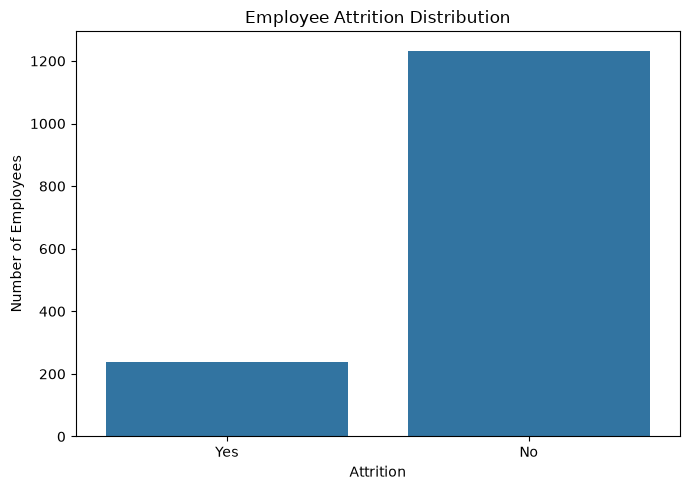

In [3]:

# Employee Attrition Analysis

attrition_counts = df["Attrition"].value_counts()
attrition_rate = (df["Attrition"].eq("Yes").mean()) * 100

print("EMPLOYEE ATTRITION ANALYSIS")
print("=" * 35)
print("Total Employees:", len(df))
print("Employees who stayed:", attrition_counts.get("No", 0))
print("Employees who left:", attrition_counts.get("Yes", 0))
print(f"Attrition Rate: {attrition_rate:.2f}%")

# Visualize attrition distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()


In [4]:

# Attrition by Overtime
print("ATTRITION BY OVERTIME")
print("=" * 45)

overtime_analysis = pd.crosstab(
    df["OverTime"],
    df["Attrition"],
    normalize="index"
) * 100

print(overtime_analysis.round(2))

# Attrition by Department
print("\nATTRITION BY DEPARTMENT")
print("=" * 45)

department_analysis = pd.crosstab(
    df["Department"],
    df["Attrition"],
    normalize="index"
) * 100

print(department_analysis.round(2))

# Attrition by Job Role
print("\nATTRITION BY JOB ROLE")
print("=" * 45)

jobrole_analysis = pd.crosstab(
    df["JobRole"],
    df["Attrition"],
    normalize="index"
) * 100

print(jobrole_analysis.round(2))


ATTRITION BY OVERTIME
Attrition     No    Yes
OverTime               
No         89.56  10.44
Yes        69.47  30.53

ATTRITION BY DEPARTMENT
Attrition                  No    Yes
Department                          
Human Resources         80.95  19.05
Research & Development  86.16  13.84
Sales                   79.37  20.63

ATTRITION BY JOB ROLE
Attrition                     No    Yes
JobRole                                
Healthcare Representative  93.13   6.87
Human Resources            76.92  23.08
Laboratory Technician      76.06  23.94
Manager                    95.10   4.90
Manufacturing Director     93.10   6.90
Research Director          97.50   2.50
Research Scientist         83.90  16.10
Sales Executive            82.52  17.48
Sales Representative       60.24  39.76


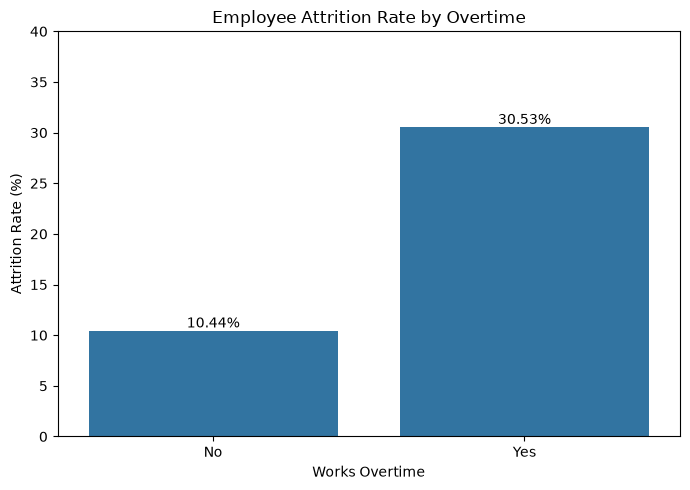

In [5]:

# Calculate attrition rate by overtime
overtime_rate = (
    df.assign(Left=df["Attrition"].eq("Yes"))
      .groupby("OverTime")["Left"]
      .mean()
      .mul(100)
)

plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=overtime_rate.index,
    y=overtime_rate.values
)

plt.title("Employee Attrition Rate by Overtime")
plt.xlabel("Works Overtime")
plt.ylabel("Attrition Rate (%)")
plt.ylim(0, 40)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.savefig("../reports/attrition_by_overtime.png", dpi=300)
plt.show()


SALARY ANALYSIS
              mean  median   min    max
Attrition                              
No         6832.74  5204.0  1051  19999
Yes        4787.09  3202.0  1009  19859

JOB SATISFACTION (1 = Low, 4 = High)
Attrition
No     2.78
Yes    2.47
Name: JobSatisfaction, dtype: float64

YEARS AT COMPANY
Attrition
No     6.0
Yes    3.0
Name: YearsAtCompany, dtype: float64


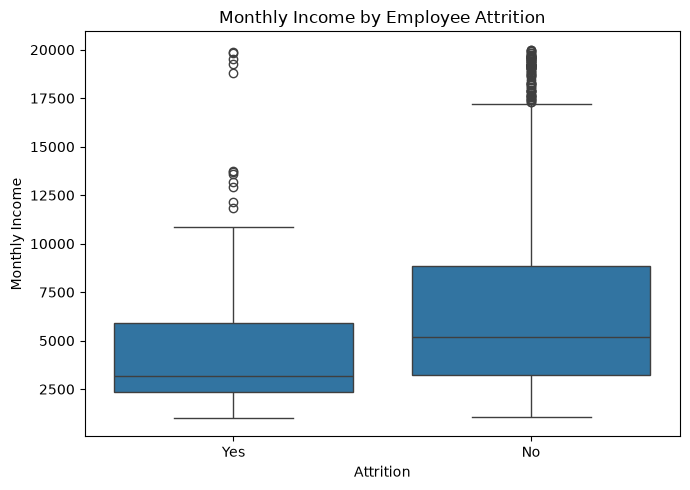

In [6]:

# Salary Analysis
print("SALARY ANALYSIS")
print("=" * 40)

salary_analysis = df.groupby("Attrition")["MonthlyIncome"].agg(
    ["mean", "median", "min", "max"]
)
print(salary_analysis.round(2))

# Job Satisfaction Analysis
print("\nJOB SATISFACTION (1 = Low, 4 = High)")
print("=" * 40)

satisfaction_analysis = df.groupby(
    "Attrition"
)["JobSatisfaction"].mean()

print(satisfaction_analysis.round(2))

# Years at Company
print("\nYEARS AT COMPANY")
print("=" * 40)

tenure_analysis = df.groupby("Attrition")["YearsAtCompany"].median()
print(tenure_analysis)

# Visualize monthly income by attrition
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Attrition", y="MonthlyIncome")
plt.title("Monthly Income by Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")
plt.tight_layout()
plt.savefig("../reports/income_by_attrition.png", dpi=300)
plt.show()


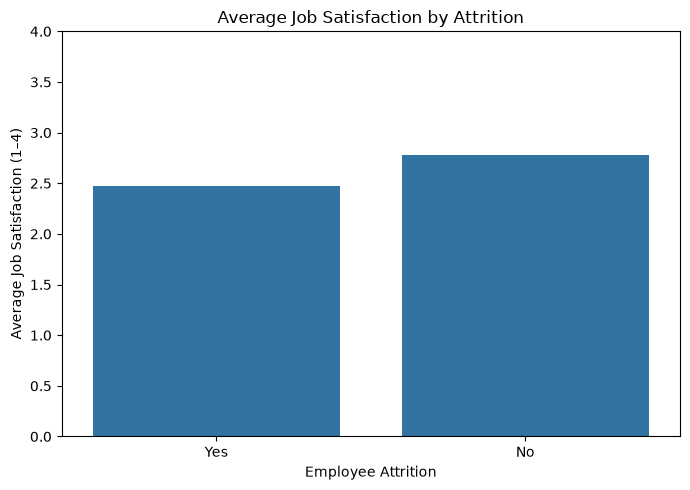

In [7]:

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Attrition",
    y="JobSatisfaction",
    errorbar=None
)

plt.title("Average Job Satisfaction by Attrition")
plt.xlabel("Employee Attrition")
plt.ylabel("Average Job Satisfaction (1–4)")
plt.ylim(0, 4)

plt.tight_layout()
plt.savefig("../reports/satisfaction_by_attrition.png", dpi=300)
plt.show()
